In [1]:
import os
print(os.getcwd())

/home/khushi/Desktop/mtp_project


In [2]:
from src.config import CWRU_RAW
from src.data_loader import load_cwru_file
print(CWRU_RAW)
print(CWRU_RAW.exists())

/home/khushi/Desktop/mtp_project/data/raw/cwru
True


In [3]:
rec = load_cwru_file(CWRU_RAW / "inner_race" / "105.mat", fs_native=12000)
print(rec.signal.shape, rec.fs, rec.rpm)

(121265,) 12000 1797.0


normal 98 {'t_rms': 0.061, 't_kurtosis': 2.967, 't_crest': 3.568}
inner race 106 {'t_rms': 0.293, 't_kurtosis': 5.54, 't_crest': 4.906}


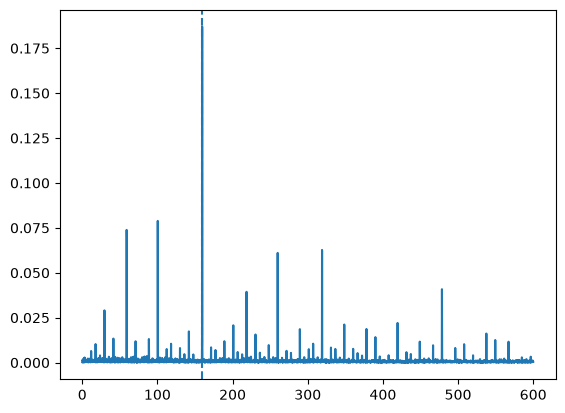

BPFI 159.9 peak/floor 272.6


In [4]:
import matplotlib.pyplot as plt
from src.config import CWRU_RAW
from src.cwru_meta import build_metadata
from src.data_loader import load_cwru_file
from src.cwru_reference import MULT
from src.signal_proc import (make_windows, time_features,
                             amplitude_spectrum, envelope_spectrum, peak_to_floor)

meta = build_metadata().set_index("file_id")
def load(fid):
    r = meta.loc[fid]
    return load_cwru_file(CWRU_RAW / r.relpath, int(r.fs_native))

normal, ir = load(98), load(106)
rpm_ir = ir.rpm or meta.loc[106, "nominal_rpm"]
f_bpfi = MULT["BPFI"] * rpm_ir / 60

for name, rec in [("normal 98", normal), ("inner race 106", ir)]:
    tf = time_features(make_windows(rec.signal))
    print(name, tf[["t_rms", "t_kurtosis", "t_crest"]].mean().round(3).to_dict())

fe, me = envelope_spectrum(ir.signal, ir.fs)
band = fe < 600
plt.plot(fe[band], me[band]); plt.axvline(f_bpfi, ls="--"); plt.show()
print("BPFI", round(f_bpfi, 1), "peak/floor", round(peak_to_floor(fe, me, f_bpfi), 1))

In [5]:
import pandas as pd
def env_of(fid):
    rec = load(fid)
    rpm = rec.rpm or meta.loc[fid, "nominal_rpm"]
    shaft = rpm / 60
    fe, me = envelope_spectrum(rec.signal, rec.fs)
    return rec, shaft, fe, me
rows = []
for fid in [98, 106, 131, 119]:
    rec, shaft, fe, me = env_of(fid)
    row = {"file": fid, "class": meta.loc[fid, "fault_type"]}
    for d in ["BPFI", "BPFO", "BSF"]:
        row[d] = round(peak_to_floor(fe, me, MULT[d] * shaft), 1)
    rows.append(row)
pd.DataFrame(rows)


,file,class,BPFI,BPFO,BSF
0,98,normal,4.9,3.4,3.7
1,106,inner_race,272.6,4.2,25.3
2,131,outer_race,11.7,835.0,151.1
3,119,ball,14.8,13.7,6.9


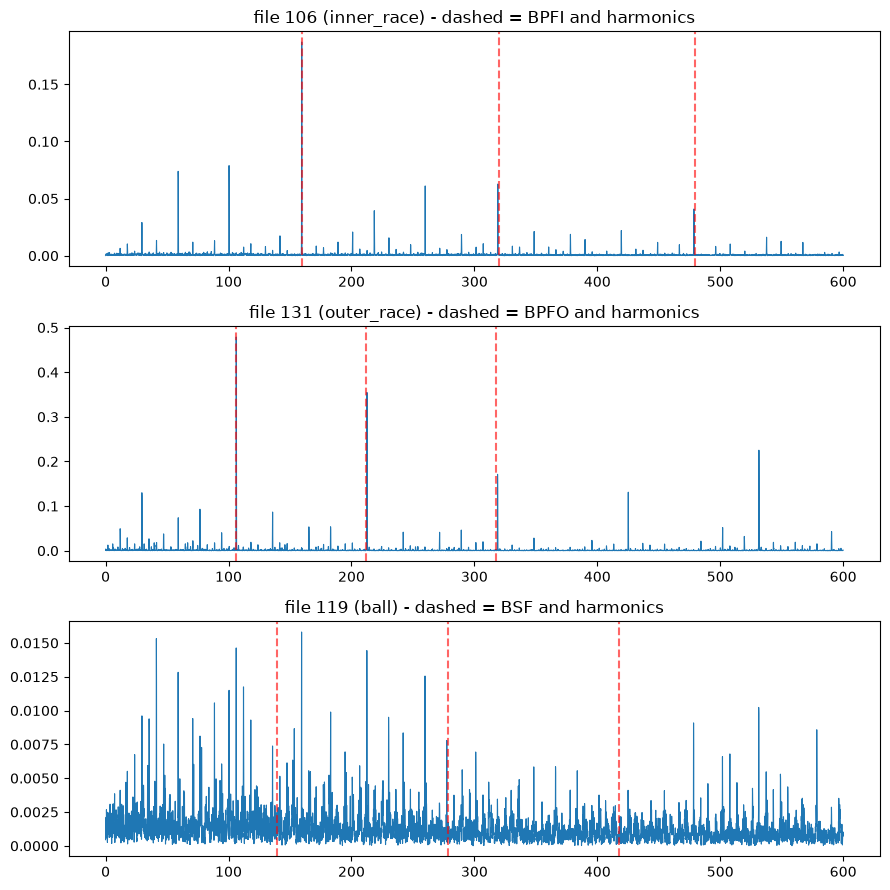

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(9, 9))
for ax, (fid, d) in zip(axes, [(106, "BPFI"), (131, "BPFO"), (119, "BSF")]):
    rec, shaft, fe, me = env_of(fid)
    f0 = MULT[d] * shaft
    m = fe < 600
    ax.plot(fe[m], me[m], lw=0.8)
    for k in (1, 2, 3):
        ax.axvline(k * f0, ls="--", c="r", alpha=0.6)
    ax.set_title(f"file {fid} ({meta.loc[fid, 'fault_type']}) - dashed = {d} and harmonics")
plt.tight_layout(); plt.show()

In [7]:
rec, shaft, fe, me = env_of(106)
f0 = MULT["BPFI"] * shaft
for k in (-2, -1, 1, 2):
    target = f0 + k * shaft
    band = (fe > target * 0.98) & (fe < target * 1.02)
    seen = fe[band][me[band].argmax()]
    print(f"BPFI {k:+d}x shaft: expected {target:6.1f} Hz, strongest peak at {seen:6.1f} Hz, "
          f"peak/floor {peak_to_floor(fe, me, target, tol_frac=0.02):.1f}")

BPFI -2x shaft: expected  100.9 Hz, strongest peak at  100.4 Hz, peak/floor 115.0
BPFI -1x shaft: expected  130.4 Hz, strongest peak at  130.0 Hz, peak/floor 11.8
BPFI +1x shaft: expected  189.5 Hz, strongest peak at  189.1 Hz, peak/floor 17.4
BPFI +2x shaft: expected  219.0 Hz, strongest peak at  218.6 Hz, peak/floor 57.5
